In [34]:
import duckdb
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
con = duckdb.connect("../warehouse/hexstrat.duckdb", read_only=True)
con.sql("select count(*) from marts.fct_opening_placements").df()

,count_star()
0,79992


In [2]:
con.sql("select count(distinct game_id) from marts.fct_opening_placements").df()

,count(DISTINCT game_id)
0,9999


In [16]:
np.median((con.sql("select count(*) from marts.fct_opening_placements group by game_id ").df()))
#8 * 10,000 games = ~80,000 total rows
#each game has 8 rows because 4 players * 2 starting moves

np.float64(8.0)

In [19]:
seats = [0, 1, 2, 3]
for seat in seats:
    total = (con.sql(f"select count(*) from marts.fct_opening_placements where seat = {seat} ").df()).iloc[0, 0]
    won = (con.sql(f"select count(*) from marts.fct_opening_placements where seat = {seat} and won = True").df()).iloc[0, 0]
    print(f'Win rate for {seat}: {won/total}')

Win rate for 0: 0.2504250425042504
Win rate for 1: 0.25682568256825683
Win rate for 2: 0.24822482248224823
Win rate for 3: 0.2445244524452445


Win rate for 15: 0.47651006711409394
Win rate for 10: 0.39505558320889334
Win rate for 1: 0.08223062381852551
Win rate for 12: 0.4567825284527838
Win rate for 11: 0.42723753131405146
Win rate for 0: 0.0442294402211472
Win rate for 8: 0.30482395342389795
Win rate for 13: 0.47632794457274824
Win rate for 5: 0.18433770588815465
Win rate for 9: 0.34614834929255395
Win rate for 14: 0.5467289719626168
Win rate for 2: 0.10915994304698623
Win rate for 7: 0.2691073512252042
Win rate for 4: 0.15198762199476315
Win rate for 6: 0.22876980594623464
Win rate for 3: 0.13209327402614907


([<matplotlib.axis.YTick at 0x12aa35090>,
 [Text(0, 15.0, '15'),
  Text(0, 10.0, '10'),
  Text(0, 1.0, '1'),
  Text(0, 12.0, '12'),
  Text(0, 11.0, '11'),
  Text(0, 0.0, '0'),
  Text(0, 8.0, '8'),
  Text(0, 13.0, '13'),
  Text(0, 5.0, '5'),
  Text(0, 9.0, '9'),
  Text(0, 14.0, '14'),
  Text(0, 2.0, '2'),
  Text(0, 7.0, '7'),
  Text(0, 4.0, '4'),
  Text(0, 6.0, '6'),
  Text(0, 3.0, '3')])

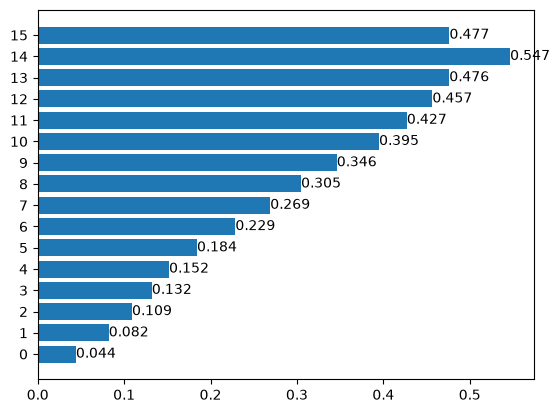

In [42]:
pips = con.sql("select distinct pips from marts.fct_opening_placements").df()['pips'].to_numpy()
df = pd.DataFrame()
win_rates = []
for pip in pips:
    total = (con.sql(f"select count(*) from marts.fct_opening_placements where pips = {pip} ").df()).iloc[0, 0]
    won = (con.sql(f"select count(*) from marts.fct_opening_placements where pips = {pip} and won = True").df()).iloc[0, 0]
    print(f'Win rate for {int(pip)}: {won/total}')
    win_rates.append(won/total)
df['pips'] = pips
df['wr'] = win_rates
bars = plt.barh(df['pips'], df['wr'])
plt.bar_label(bars, fmt = "%.3f")
plt.yticks(df['pips'])

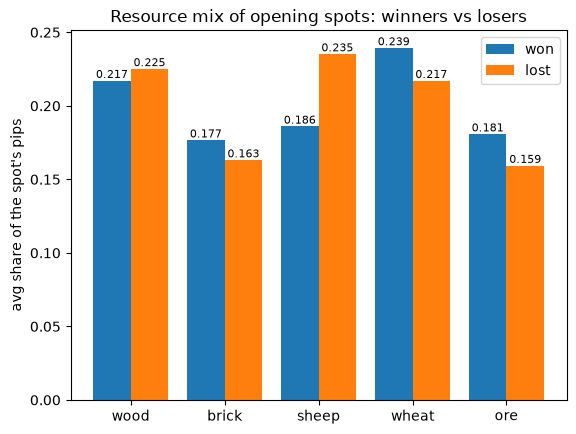

In [54]:
won = con.sql('select (pips_wood/pips), (pips_brick/pips), (pips_sheep/pips), (pips_wheat/pips), (pips_ore/pips) from marts.fct_opening_placements where won = True').df()
lost = con.sql('select (pips_wood/pips), (pips_brick/pips), (pips_sheep/pips), (pips_wheat/pips), (pips_ore/pips) from marts.fct_opening_placements where won = False').df()
props = con.sql("""
    select
        won,
        avg(pips_wood  / pips) as wood,
        avg(pips_brick / pips) as brick,
        avg(pips_sheep / pips) as sheep,
        avg(pips_wheat / pips) as wheat,
        avg(pips_ore   / pips) as ore
    from marts.fct_opening_placements
    where pips > 0
    group by won
""").df().set_index("won")

resources = ["wood", "brick", "sheep", "wheat", "ore"]
x = np.arange(len(resources))   # one slot per resource: 0..4
w = 0.4                          # bar width; two bars per slot

bars_won  = plt.bar(x - w/2, props.loc[True,  resources], w, label="won")
bars_lost = plt.bar(x + w/2, props.loc[False, resources], w, label="lost")
plt.bar_label(bars_won,  fmt="%.3f", fontsize=8)
plt.bar_label(bars_lost, fmt="%.3f", fontsize=8)

plt.xticks(x, resources)
plt.ylabel("avg share of the spot's pips")
plt.title("Resource mix of opening spots: winners vs losers")
plt.legend()
plt.show()

In [67]:
totalGames = con.sql('select count(*) from marts.fct_opening_placements group by player').df().to_numpy()
wins = con.sql('select count(*) from marts.fct_opening_placements where won = True group by player').df().to_numpy()
for i in range(4):
    print(wins[i] / totalGames[i])

[0.18751875]
[0.1880188]
[0.44294429]
[0.18151815]
